# Smart Freight: Shipping Days Prediction

## Objective

To predict the actual number of shipping days for an order using
pre-shipment order, shipping, location, and time-related information.

Target Variable:

`Days for shipping (real)`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import joblib

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

Upload the cleaned CSV

In [2]:
uploaded = files.upload()

Saving DataCo_Cleaned-2.csv to DataCo_Cleaned-2 (1).csv


Load the dataset

In [3]:
df = pd.read_csv("DataCo_Cleaned-2.csv", encoding="latin1")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (59606, 35)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Name,Customer City,Customer Country,Customer Segment,...,Order State,Order Status,Product Name,Product Price,Shipping Mode,order_month,order_day,order_weekday,order_hour,is_weekend
0,DEBIT,3,4,91.250000,314.640015,0.0,Sporting Goods,Caguas,Puerto Rico,Consumer,...,Java Occidental,COMPLETE,Smart watch,327.75,Standard Class,1.0,31.0,2.0,22.0,0
1,TRANSFER,5,4,-249.089996,311.359985,1.0,Sporting Goods,Caguas,Puerto Rico,Consumer,...,RajastÃ¡n,PENDING,Smart watch,327.75,Standard Class,1.0,13.0,5.0,12.0,1
2,CASH,4,4,-247.779999,309.720001,0.0,Sporting Goods,San Jose,EE. UU.,Consumer,...,RajastÃ¡n,CLOSED,Smart watch,327.75,Standard Class,1.0,13.0,5.0,12.0,1
3,DEBIT,3,4,22.860001,304.809998,0.0,Sporting Goods,Los Angeles,EE. UU.,Home Office,...,Queensland,COMPLETE,Smart watch,327.75,Standard Class,1.0,13.0,5.0,11.0,1
4,PAYMENT,2,4,134.210007,298.250000,0.0,Sporting Goods,Caguas,Puerto Rico,Corporate,...,Queensland,PENDING_PAYMENT,Smart watch,327.75,Standard Class,1.0,13.0,5.0,11.0,1


Dataset information

In [4]:
df.info()

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59606 entries, 0 to 59605
Data columns (total 35 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Type                           59606 non-null  object 
 1   Days for shipping (real)       59606 non-null  int64  
 2   Days for shipment (scheduled)  59606 non-null  int64  
 3   Benefit per order              59606 non-null  float64
 4   Sales per customer             59606 non-null  float64
 5   Late_delivery_risk             59605 non-null  float64
 6   Category Name                  59605 non-null  object 
 7   Customer City                  59605 non-null  object 
 8   Customer Country               59605 non-null  object 
 9   Customer Segment               59605 non-null  object 
 10  Customer State                 59605 non-null  object 
 11  Department Name                59605 non-null  object 
 12  Latitude                       59605 non-null 

In [5]:
df = df.dropna().copy()

print("Dataset shape after removing missing row:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Dataset shape after removing missing row: (59605, 35)
Remaining missing values: 0


Target distribution

count    59605.000000
mean         3.399446
std          1.634352
min          0.000000
25%          2.000000
50%          3.000000
75%          5.000000
max          6.000000
Name: Days for shipping (real), dtype: float64


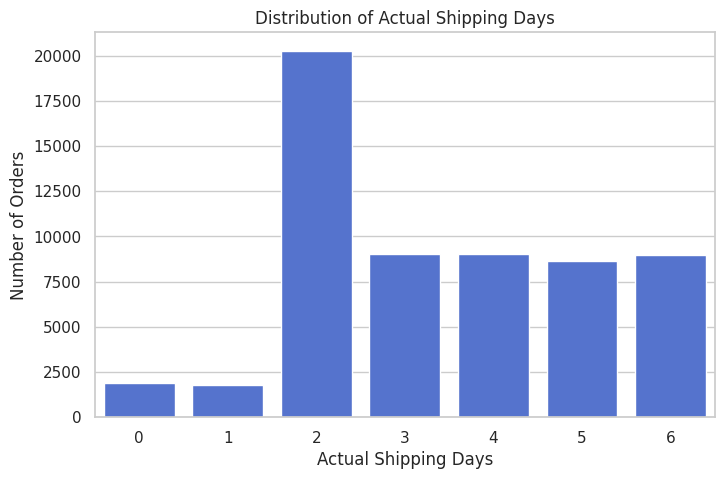

In [6]:
target_col = "Days for shipping (real)"

print(df[target_col].describe())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=target_col, color="royalblue")
plt.title("Distribution of Actual Shipping Days")
plt.xlabel("Actual Shipping Days")
plt.ylabel("Number of Orders")
plt.show()

Shipping mode EDA

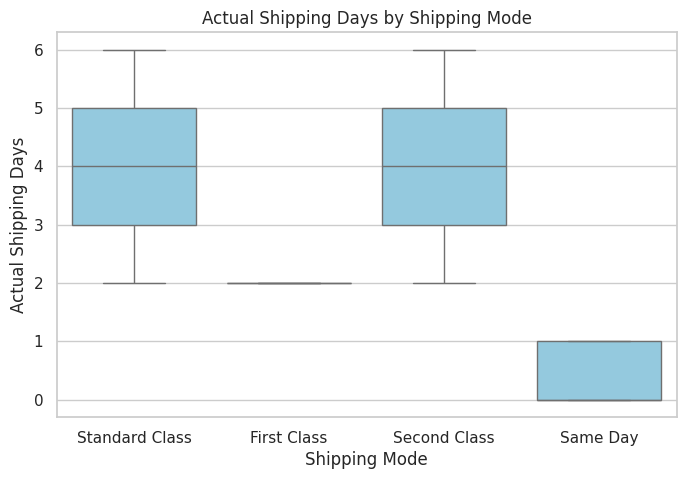

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Shipping Mode",
    y=target_col,
    color="skyblue"
)

plt.title("Actual Shipping Days by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Actual Shipping Days")
plt.show()

Scheduled versus actual shipping days

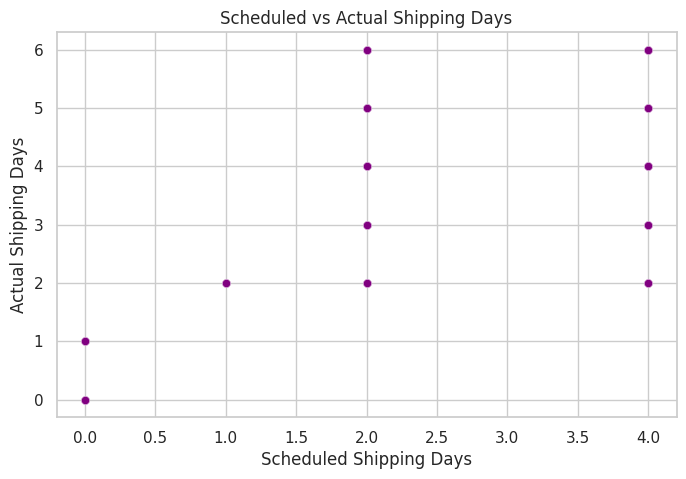

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df.sample(min(5000, len(df)), random_state=42),
    x="Days for shipment (scheduled)",
    y="Days for shipping (real)",
    alpha=0.35,
    color="purple"
)

plt.title("Scheduled vs Actual Shipping Days")
plt.xlabel("Scheduled Shipping Days")
plt.ylabel("Actual Shipping Days")
plt.show()

Correlation heatmap

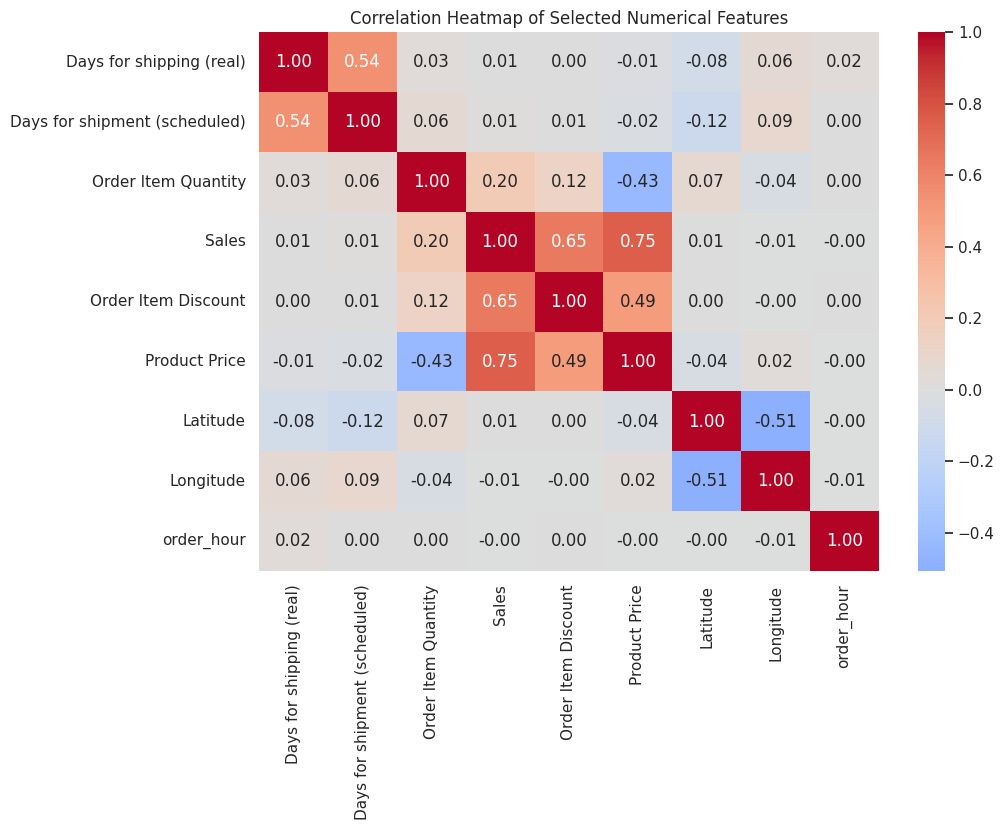

In [9]:
numeric_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Order Item Quantity",
    "Sales",
    "Order Item Discount",
    "Product Price",
    "Latitude",
    "Longitude",
    "order_hour"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[numeric_columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Selected Numerical Features")
plt.show()

Feature selection explanation

In [10]:
target_col = "Days for shipping (real)"

feature_cols = [
    # Shipping information
    "Days for shipment (scheduled)",
    "Shipping Mode",
    "Type",

    # Customer and geography
    "Customer Segment",
    "Market",
    "Order Region",
    "Order Country",

    # Product information
    "Category Name",
    "Department Name",
    "Order Item Quantity",
    "Sales",
    "Order Item Discount",
    "Product Price",

    # Location coordinates
    "Latitude",
    "Longitude",

    # Extracted time features
    "order_month",
    "order_day",
    "order_weekday",
    "order_hour",
    "is_weekend"
]

X = df[feature_cols].copy()
y = df[target_col].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (59605, 20)
Target shape: (59605,)


Train-test split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (47684, 20)
Testing set: (11921, 20)


Preprocessing pipeline

In [12]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['Days for shipment (scheduled)', 'Order Item Quantity', 'Sales', 'Order Item Discount', 'Product Price', 'Latitude', 'Longitude', 'order_month', 'order_day', 'order_weekday', 'order_hour', 'is_weekend']

Categorical features: ['Shipping Mode', 'Type', 'Customer Segment', 'Market', 'Order Region', 'Order Country', 'Category Name', 'Department Name']


Model evaluation function

In [14]:
def evaluate_model(name, model):
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    start_time = time.time()

    pipeline.fit(X_train, y_train)

    training_time = time.time() - start_time

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    return {
        "Model": name,
        "Pipeline": pipeline,
        "Predictions": predictions,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R² Score": r2,
        "Training Time (sec)": training_time
    }

Linear Regression

In [15]:
linear_result = evaluate_model(
    "Linear Regression",
    LinearRegression()
)

print("Linear Regression")
print("MAE:", round(linear_result["MAE"], 3))
print("RMSE:", round(linear_result["RMSE"], 3))
print("R² Score:", round(linear_result["R² Score"], 3))

Linear Regression
MAE: 0.967
RMSE: 1.246
R² Score: 0.423


Decision Tree

In [16]:
dt_result = evaluate_model(
    "Decision Tree Regressor",
    DecisionTreeRegressor(
        max_depth=15,
        random_state=42
    )
)

print("Decision Tree Regressor")
print("MAE:", round(dt_result["MAE"], 3))
print("RMSE:", round(dt_result["RMSE"], 3))
print("R² Score:", round(dt_result["R² Score"], 3))

Decision Tree Regressor
MAE: 0.882
RMSE: 1.228
R² Score: 0.44


Random Forest

In [17]:
rf_result = evaluate_model(
    "Random Forest Regressor",
    RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    )
)

print("Random Forest Regressor")
print("MAE:", round(rf_result["MAE"], 3))
print("RMSE:", round(rf_result["RMSE"], 3))
print("R² Score:", round(rf_result["R² Score"], 3))

Random Forest Regressor
MAE: 0.887
RMSE: 1.192
R² Score: 0.472


Compare all models

In [18]:
results = [linear_result, dt_result, rf_result]

results_df = pd.DataFrame([
    {
        "Model": result["Model"],
        "MAE": result["MAE"],
        "MSE": result["MSE"],
        "RMSE": result["RMSE"],
        "R² Score": result["R² Score"],
        "Training Time (sec)": result["Training Time (sec)"]
    }
    for result in results
]).sort_values(by="RMSE").reset_index(drop=True)

results_df

,Model,MAE,MSE,RMSE,R² Score,Training Time (sec)
0,Random Forest Regressor,0.887432,1.420311,1.191768,0.472119,79.155602
1,Decision Tree Regressor,0.882386,1.507787,1.227920,0.439607,4.454972
2,Linear Regression,0.967004,1.551970,1.245781,0.423185,1.847858


Model comparison chart

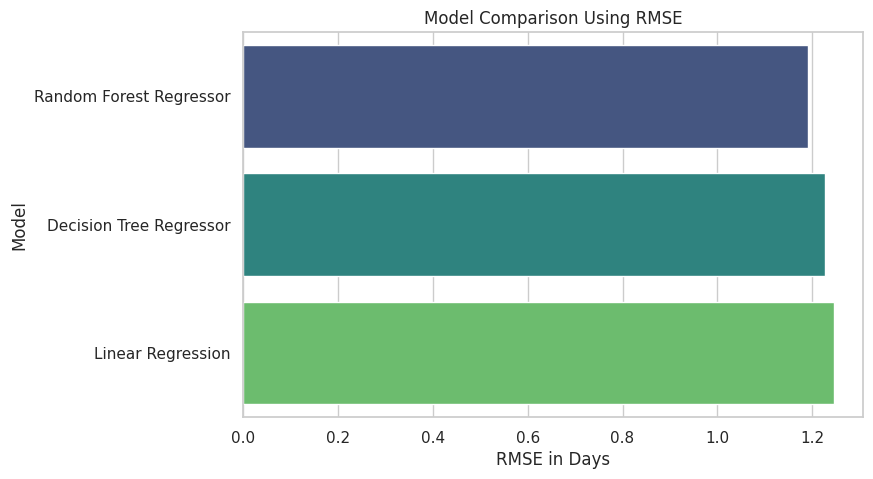

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="RMSE",
    y="Model",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Model Comparison Using RMSE")
plt.xlabel("RMSE in Days")
plt.ylabel("Model")
plt.show()

Select the final model

In [21]:
best_result = min(results, key=lambda result: result["RMSE"])

final_model = best_result["Pipeline"]
final_predictions = best_result["Predictions"]

print("Final Selected Model:", best_result["Model"])
print("MAE:", round(best_result["MAE"], 3), "days")
print("RMSE:", round(best_result["RMSE"], 3), "days")
print("R² Score:", round(best_result["R² Score"], 3))

Final Selected Model: Random Forest Regressor
MAE: 0.887 days
RMSE: 1.192 days
R² Score: 0.472


Actual versus predicted

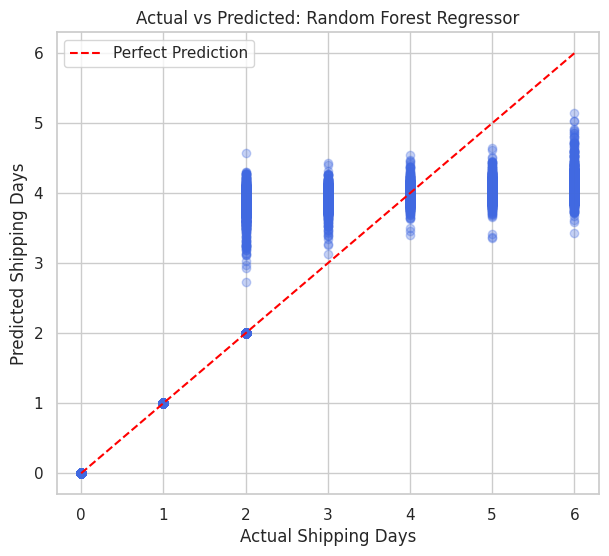

In [22]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.30,
    color="royalblue"
)

minimum = min(y_test.min(), final_predictions.min())
maximum = max(y_test.max(), final_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.title(f"Actual vs Predicted: {best_result['Model']}")
plt.xlabel("Actual Shipping Days")
plt.ylabel("Predicted Shipping Days")
plt.legend()
plt.show()

Residual distribution

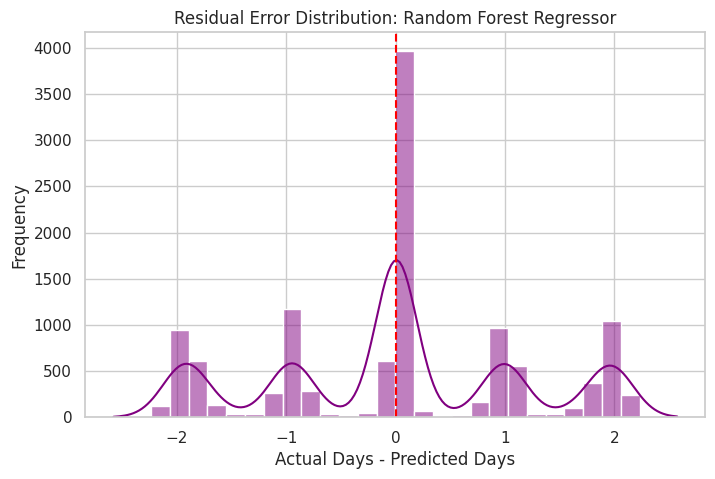

In [23]:
residuals = y_test - final_predictions

plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    bins=30,
    kde=True,
    color="purple"
)

plt.axvline(0, color="red", linestyle="--")

plt.title(f"Residual Error Distribution: {best_result['Model']}")
plt.xlabel("Actual Days - Predicted Days")
plt.ylabel("Frequency")
plt.show()

Feature importance

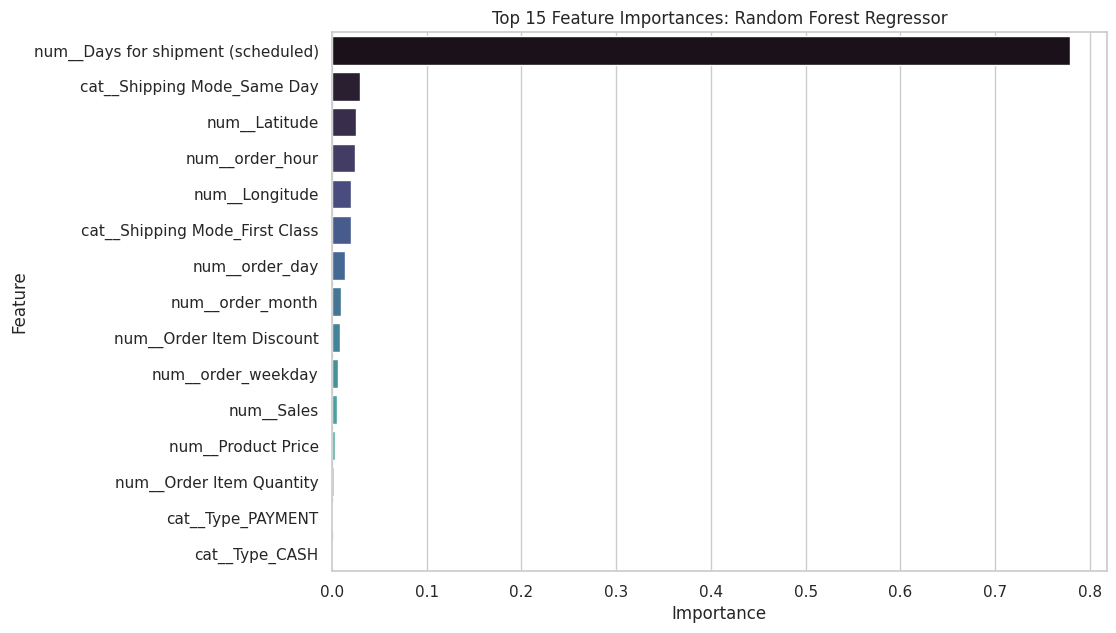

,Feature,Importance
0,num__Days for shipment (scheduled),0.779034
13,cat__Shipping Mode_Same Day,0.029966
5,num__Latitude,0.025099
10,num__order_hour,0.024483
6,num__Longitude,0.020094
12,cat__Shipping Mode_First Class,0.019996
8,num__order_day,0.014020
7,num__order_month,0.009192
3,num__Order Item Discount,0.008932
9,num__order_weekday,0.006983


In [24]:
tree_model = final_model.named_steps["model"]

feature_names = final_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
).head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="mako",
    legend=False
)

plt.title(f"Top 15 Feature Importances: {best_result['Model']}")
plt.show()

importance_df

Save the full final pipeline

In [25]:
joblib.dump(
    final_model,
    "smart_freight_model_pipeline.joblib"
)

joblib.dump(
    feature_cols,
    "smart_freight_feature_list.joblib"
)

print("Model pipeline and feature list saved successfully.")

Model pipeline and feature list saved successfully.


Download model files

In [26]:
files.download("smart_freight_model_pipeline.joblib")
files.download("smart_freight_feature_list.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

Three regression models were trained to predict actual shipping days:
Linear Regression, Decision Tree Regressor, and Random Forest Regressor.

The final model was selected using the lowest RMSE, followed by MAE and R²
score. The selected model pipeline contains preprocessing and model training
together, so it can safely be used in the Smart Freight web application.